# 04 — A fusão que não aconteceu

**A pergunta:** se a fusão Azul + GOL tivesse acontecido, quantos mercados
passariam dos limites de concentração do CADE, e quantas pessoas voam
neles?

A fusão chegou a ser negociada. Em 15/01/2025, a Abra, controladora da
GOL, e a Azul assinaram um memorando de entendimentos; em 25/09/2025, a
Abra encerrou as negociações. As datas, com as fontes e as frases
exatas, estão no README, na seção "A fusão Azul + GOL".

Faz parte da [etapa 8](../README.md#etapas) do projeto. Os dados vêm de
`dados/marts/fusao.parquet`, que o `construir.py` monta a partir da coleta
de 13/10/2026: um registro por janela e mercado, com o HHI antes e depois
de juntar as duas, a variação e a leitura do guia do CADE.

## 1. As regras, fixadas antes de rodar

- **Duas janelas de 12 meses.** 2024, de janeiro a dezembro: o mercado que
  a fusão encontraria, os 12 meses antes do memorando. E os 12 meses mais
  recentes da base: o mercado de hoje. Se a conclusão mudar entre as duas,
  as duas aparecem.
- **Participação pelos passageiros pagos de voo regular**, somados na
  janela, como no notebook 02. O passageiro é de quem operou o voo, então
  o codeshare entre Azul e GOL, que valeu de maio de 2024 a setembro de
  2025, não muda a conta.
- **Simulação estática:** ninguém reage, ninguém entra e ninguém sai. É o
  mercado de cada janela com as duas companhias somadas, e não uma
  previsão do que teria acontecido.
- **A régua é a do [Guia para Análise de Atos de Concentração Horizontal
  do CADE](https://cdn.cade.gov.br/Portal/centrais-de-conteudo/publicacoes/guias-do-CADE/guia-para-analise-de-atos-de-concentracao-horizontal.pdf) (2016)**, seção 2.4.2. Operações com variação de HHI
  abaixo de 100 pontos "provavelmente não geram efeitos competitivos
  adversos"; mercado que fica abaixo de 1.500 não preocupa; mercado de
  1.500 a 2.500 com variação acima de 100, e mercado acima de 2.500 com
  variação de 100 a 200, "têm potencial de gerar preocupações
  concorrenciais"; mercado acima de 2.500 com variação acima de 200
  "presumivelmente geram aumento de poder de mercado". Daqui em diante,
  **cruzar a linha** é cair numa dessas duas últimas leituras.
- **É triagem, não veredito.** O próprio guia avisa: "A 'regra do HHI',
  como indicativa de nexo causal é uma suposição inicial, sensível a
  outros argumentos." 

In [1]:
import pandas as pd

URL = "https://raw.githubusercontent.com/ivadivad/voos-em-numeros/coleta-2026-10-13/dados/marts/fusao.parquet"
DIM_MERCADO = "https://raw.githubusercontent.com/ivadivad/voos-em-numeros/coleta-2026-10-13/dados/marts/dim_mercado.parquet"
fusao = pd.read_parquet(URL)
mercado = pd.read_parquet(DIM_MERCADO).set_index("mercado")
fusao = fusao.join(mercado[["nome"]], on="mercado")
fusao["distancia_km"] = fusao["mercado"].map(mercado["distancia_km"].astype(float))
for coluna in ["inicio", "fim"]:
    fusao[coluna] = pd.to_datetime(fusao[coluna])
CRUZA = ["potencial preocupação", "presunção de poder de mercado"]
fusao["cruza"] = fusao["leitura"].isin(CRUZA)
JANELAS = ["2024", "12 meses mais recentes"]
for janela in JANELAS:
    j = fusao[fusao["janela"] == janela]
    print(f"{janela}: {j['inicio'].min():%m/%Y} a {j['fim'].max():%m/%Y}, {len(j)} mercados, "
          f"{j['passageiros'].sum()} passageiros regulares")

2024: 01/2024 a 12/2024, 503 mercados, 90078553 passageiros regulares
12 meses mais recentes: 09/2025 a 08/2026, 467 mercados, 102101878 passageiros regulares


As duas janelas são as declaradas: 2024, de 01/2024 a 12/2024, com 503
mercados e 90.078.553 passageiros regulares, e os 12 meses mais recentes, de
09/2025 a 08/2026, com 467 mercados e 102.101.878 passageiros. O passageiro
aqui é o de cada voo: quem troca de avião conta uma vez em cada um.

## 2. Quantos mercados cruzariam a linha

In [2]:
print("o mercado menos concentrado antes da fusão, em cada janela (HHI):",
      fusao.groupby("janela")["hhi_antes"].min().round(0).to_dict())
print("mercados com HHI antes até 2.500:", int((fusao["hhi_antes"] <= 2500).sum()), "\n")

resumo = fusao.groupby(["janela", "leitura"]).agg(mercados=("mercado", "size"), passageiros=("passageiros", "sum"))
resumo["% dos passageiros"] = resumo["passageiros"] / resumo.groupby(level="janela")["passageiros"].transform("sum") * 100
print(resumo.round(1).to_string(), "\n")

cruzam = fusao[fusao["cruza"]]
print("cruzariam a linha:", cruzam.groupby("janela").size().to_dict())
print("mercados com Azul e GOL:", fusao[(fusao["participacao_azul"] > 0) & (fusao["participacao_gol"] > 0)]
      .groupby("janela").size().to_dict())
print("concorrentes antes -> depois, nos que cruzariam a linha:")
transicao = cruzam["concorrentes_antes"].astype(str) + " -> " + cruzam["concorrentes_depois"].astype(str)
print(pd.crosstab(cruzam["janela"], transicao, colnames=["concorrentes"]).to_string(), "\n")
em_2024, recentes = (set(cruzam.loc[cruzam["janela"] == j, "mercado"]) for j in JANELAS)
print(f"cruzariam nas duas janelas: {len(em_2024 & recentes)}; só em 2024: {len(em_2024 - recentes)}; "
      f"só nos 12 meses mais recentes: {len(recentes - em_2024)}")

o mercado menos concentrado antes da fusão, em cada janela (HHI): {'12 meses mais recentes': 3334.0, '2024': 2954.0}
mercados com HHI antes até 2.500: 0 

                                                      mercados  passageiros  % dos passageiros
janela                 leitura                                                                
12 meses mais recentes presunção de poder de mercado        66     72508048               71.0
                       variação pequena                    401     29593830               29.0
2024                   potencial preocupação                 1        29578                0.0
                       presunção de poder de mercado        78     67359666               74.8
                       variação pequena                    424     22689309               25.2 

cruzariam a linha: {'12 meses mais recentes': 66, '2024': 79}
mercados com Azul e GOL: {'12 meses mais recentes': 93, '2024': 97}
concorrentes antes -> depois, nos que cruzariam 

**Antes de qualquer fusão, todo mercado já é altamente concentrado pela
régua do guia.** O menos concentrado tem HHI de 2.954 em 2024 e de 3.334
nos 12 meses mais recentes, e nenhum fica até 2.500. A leitura do guia,
aqui, depende só da variação.

**Em 2024, 79 dos 503 mercados cruzariam a linha, e eles levam 74,8% dos
passageiros regulares:** 78 com presunção de aumento de poder de mercado e
1 com potencial de preocupação. Nos 12 meses mais recentes, são 66 de 467,
todos com presunção, com 71,0% dos passageiros. Nos outros, a variação é
pequena: Azul e GOL quase não se encontram neles.

A conclusão não muda entre as janelas: 58 mercados cruzariam a linha nas
duas. E, na maioria, a fusão tiraria um concorrente: em 2024, 49
passariam de três grupos pra dois, 18 de dois pra um e 2 de quatro pra
três.

In [3]:
for janela in JANELAS:
    maiores = cruzam[cruzam["janela"] == janela].nlargest(10, "passageiros")
    tabela = pd.DataFrame({
        "mercado": maiores["nome"],
        "passageiros (mil)": (maiores["passageiros"] / 1000).round(0).astype(int),
        "Azul (%)": (maiores["participacao_azul"] * 100).round(1),
        "GOL (%)": (maiores["participacao_gol"] * 100).round(1),
        "HHI antes": maiores["hhi_antes"].round(0).astype(int),
        "HHI depois": maiores["hhi_depois"].round(0).astype(int),
        "variação": maiores["delta_hhi"].round(0).astype(int),
    })
    print(f"os 10 maiores que cruzariam a linha, {janela}")
    print(tabela.to_string(index=False), "\n")

os 10 maiores que cruzariam a linha, 2024
                        mercado  passageiros (mil)  Azul (%)  GOL (%)  HHI antes  HHI depois  variação
     Rio de Janeiro – São Paulo               6907      22.6     38.8       3497        5255      1758
     Belo Horizonte – São Paulo               4204      40.4     24.5       3464        5443      1979
           São Paulo – Brasília               4080      18.8     34.7       3723        5024      1301
             São Paulo – Recife               3687      49.8     24.8       3741        6214      2474
    São Paulo – Curitiba (SBCT)               3510      31.1     25.2       3514        5078      1565
           São Paulo – Salvador               3196      13.1     42.4       3952        5060      1108
      São Paulo – Florianópolis               2835      12.5     35.0       4069        4944       875
            São Paulo – Goiânia               2216      16.1     33.9       3908        5000      1092
São Paulo – Porto Alegre (SBPA)

**Os maiores mercados atingidos são todos de São Paulo, e são os mesmos
dez nas duas janelas, em outra ordem.** Rio–São Paulo, o maior, teve 6907
mil passageiros em 2024, com a GOL em 38,8% e a Azul em 22,6%: o HHI iria
de 3.497 a 5.255. Em São Paulo–Recife, onde a Azul tinha 49,8%, a
variação é a maior dos dez em 2024, 2.474 pontos.

HHI antes: [3413, 4402] | HHI depois: [4944, 6214]


gravado em graficos/04-hhi-antes-e-depois.png


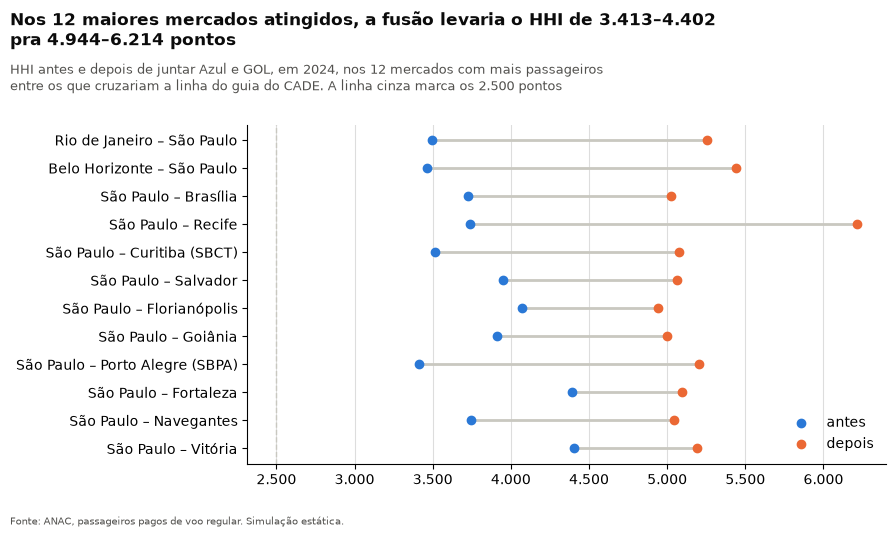

In [4]:
import os
import sys
import urllib.request

if os.path.exists("../visual.py"):
    sys.path.insert(0, "..")
else:  # fora do repositorio (no Colab): o padrao visual vem pela URL bruta
    urllib.request.urlretrieve("https://raw.githubusercontent.com/ivadivad/voos-em-numeros/coleta-2026-10-13/visual.py", "visual.py")
from visual import AZUL, CINZA, LARANJA, grafico, numero_br, salvar
import matplotlib.ticker as mticker

maiores = cruzam[cruzam["janela"] == "2024"].nlargest(12, "passageiros").iloc[::-1]
faixa_antes = [round(maiores["hhi_antes"].min()), round(maiores["hhi_antes"].max())]
faixa_depois = [round(maiores["hhi_depois"].min()), round(maiores["hhi_depois"].max())]
print("HHI antes:", faixa_antes, "| HHI depois:", faixa_depois)
fig, ax = grafico(f"Nos 12 maiores mercados atingidos, a fusão levaria o HHI de {numero_br(faixa_antes[0])}–"
                  f"{numero_br(faixa_antes[1])}\npra {numero_br(faixa_depois[0])}–{numero_br(faixa_depois[1])} pontos",
                  subtitulo="HHI antes e depois de juntar Azul e GOL, em 2024, nos 12 mercados com mais passageiros\n"
                            "entre os que cruzariam a linha do guia do CADE. A linha cinza marca os 2.500 pontos",
                  fonte="Fonte: ANAC, passageiros pagos de voo regular. Simulação estática.", figsize=(9, 5.4))
y = range(len(maiores))
ax.hlines(y, maiores["hhi_antes"], maiores["hhi_depois"], color=CINZA, linewidth=2)
ax.scatter(maiores["hhi_antes"], y, color=AZUL, zorder=3, label="antes")
ax.scatter(maiores["hhi_depois"], y, color=LARANJA, zorder=3, label="depois")
ax.axvline(2500, color=CINZA, linewidth=1, linestyle="--")
ax.set_yticks(list(y), maiores["nome"])
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color="#dddddd", linewidth=0.8)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(numero_br))
ax.legend(frameon=False, loc="lower right")
print("gravado em graficos/" + os.path.basename(salvar(fig, "04-hhi-antes-e-depois.png")))

Nos 12 maiores mercados atingidos em 2024, o HHI, que ia de 3.413 a
4.402, passaria a ficar entre 4.944 e 6.214 pontos. A linha de 2.500 do
guia ficou pra trás antes da fusão: o que ela faria é concentrar ainda
mais mercados que já são altamente concentrados.

## 3. A tarifa nesses mercados

A comparação, fixada antes de rodar: a tarifa por km de 2024 (receita
sobre assentos-km, as duas somadas no ano), nas mesmas quatro faixas de
distância do notebook 03, em dois grupos: os mercados que cruzariam a
linha e os que ficam fora da fusão, onde a variação é pequena. Como todo
mercado já é altamente concentrado, os de fora são o retrato de mercados
concentrados sem a fusão.

Depois, uma ordem de grandeza do que estaria em jogo: quanto a receita
das tarifas registradas nos mercados atingidos subiria se o km neles
custasse o mesmo que (a) nos mercados fora da fusão da mesma faixa, ou
(b) nos mercados fora da fusão que já têm, hoje, o número de concorrentes
que os atingidos teriam depois, na mesma faixa. São dois cenários, e não
uma previsão: o notebook 03 mostrou que concorrência e preço andam
juntos, não que um cause o outro.

In [5]:
URL_MERCADO_MES = "https://raw.githubusercontent.com/ivadivad/voos-em-numeros/coleta-2026-10-13/dados/marts/mercado_mes.parquet"
mart = pd.read_parquet(URL_MERCADO_MES)
mart["mes"] = pd.to_datetime(mart["mes"])
tarifa_2024 = mart[mart["mes"].dt.year == 2024].groupby("mercado")[["receita", "assentos_vendidos", "assentos_km"]].sum(min_count=1)
em_2024 = fusao[fusao["janela"] == "2024"].set_index("mercado").join(tarifa_2024)
em_2024 = em_2024[em_2024["assentos_km"].notna() & (em_2024["assentos_vendidos"] > 0)].copy()
em_2024["grupo"] = em_2024["cruza"].map({True: "cruzariam a linha", False: "fora da fusão"})
FAIXAS = ["até 500 km", "500 a 1.000 km", "1.000 a 2.000 km", "acima de 2.000 km"]
em_2024["faixa"] = pd.cut(em_2024["distancia_km"], [0, 500, 1000, 2000, float("inf")], labels=FAIXAS)

s = em_2024.groupby(["faixa", "grupo"], observed=True).agg(
    mercados=("passageiros", "size"), receita=("receita", "sum"),
    assentos=("assentos_vendidos", "sum"), assentos_km=("assentos_km", "sum"))
s["tarifa por km (R$)"] = s["receita"] / s["assentos_km"]
s["distância média (km)"] = s["assentos_km"] / s["assentos"]
um_so = em_2024[~em_2024["cruza"]].groupby("faixa", observed=True)["concorrentes_antes"].apply(lambda c: (c == 1).mean() * 100)
print("2024, mercados com tarifa e distância")
print(s[["mercados", "tarifa por km (R$)", "distância média (km)"]]
      .round({"tarifa por km (R$)": 3, "distância média (km)": 0}).to_string(), "\n")
km = s["tarifa por km (R$)"].unstack("grupo")
print("fora da fusão sobre os que cruzariam (%):", ((km["fora da fusão"] / km["cruzariam a linha"] - 1) * 100).round(1).to_dict())
print("fora da fusão, % com um concorrente só:", um_so.round(0).to_dict())

2024, mercados com tarifa e distância
                                     mercados  tarifa por km (R$)  distância média (km)
faixa             grupo                                                                
até 500 km        cruzariam a linha        18               1.114                 373.0
                  fora da fusão           151               1.345                 390.0
500 a 1.000 km    cruzariam a linha        28               0.681                 709.0
                  fora da fusão           114               0.771                 772.0
1.000 a 2.000 km  cruzariam a linha        25               0.410                1546.0
                  fora da fusão           100               0.500                1392.0
acima de 2.000 km cruzariam a linha         8               0.338                2280.0
                  fora da fusão            31               0.335                2419.0 

fora da fusão sobre os que cruzariam (%): {'até 500 km': 20.8, '500 a 1.000 km':

**Até 2.000 km, os mercados que a fusão atingiria cobram menos por km que
os que ficam fora dela.** Em 2024, o km nos mercados de fora custa 20,8%
mais até 500 km, 13,3% mais de 500 a 1.000 km e 21,9% mais de 1.000 a
2.000 km; acima de 2.000 km, quase o mesmo (−0,8%). É o padrão do notebook
03 visto por outro lado: os de fora são, em geral, de um concorrente só
(de 74% a 91% deles, conforme a faixa), e os atingidos têm hoje a Azul, a
GOL e, quase sempre, um terceiro grupo.

A distância média dentro da faixa é parecida, mas não igual. De 1.000 a
2.000 km, os atingidos são mais longos (1.546 km contra 1.392), e parte da
diferença ali é distância; nas outras faixas eles são mais curtos, o que
joga no sentido contrário.

In [6]:
# a) o preco por km dos que cruzariam igual ao dos ja concentrados da mesma faixa
alvo = s.xs("cruzariam a linha", level="grupo")
referencia = s.xs("fora da fusão", level="grupo")
pela_faixa = (alvo["receita"] * (referencia["tarifa por km (R$)"] / alvo["tarifa por km (R$)"] - 1)).sum()

# b) igual ao dos mercados que ja tem, hoje, o numero de concorrentes que eles teriam depois
em_2024["depois"] = em_2024["concorrentes_depois"].clip(upper=3)
em_2024["antes"] = em_2024["concorrentes_antes"].clip(upper=3)
ref = em_2024[~em_2024["cruza"]].groupby(["faixa", "antes"], observed=True).agg(
    mercados_ref=("receita", "size"), receita=("receita", "sum"), assentos_km=("assentos_km", "sum"))
ref["km_ref"] = ref["receita"] / ref["assentos_km"]
ref.index.names = ["faixa", "depois"]
atingidos = em_2024[em_2024["cruza"]].groupby(["faixa", "depois"], observed=True).agg(
    mercados=("receita", "size"), receita=("receita", "sum"), assentos_km=("assentos_km", "sum"))
atingidos["km"] = atingidos["receita"] / atingidos["assentos_km"]
par = atingidos.join(ref[["mercados_ref", "km_ref"]], how="inner")
par["diferença (%)"] = (par["km_ref"] / par["km"] - 1) * 100
pela_estrutura = (par["receita"] * (par["km_ref"] / par["km"] - 1)).sum()
fora_da_conta = atingidos.loc[~atingidos.index.isin(par.index), "receita"].sum()

print(f"receita das tarifas registradas em 2024 nos que cruzariam a linha: R$ {alvo['receita'].sum() / 1e9:.2f} bi")
print(f"a) pela faixa: R$ {pela_faixa / 1e9:.2f} bi a mais por ano")
print(f"   (R$ {pela_faixa / alvo['receita'].sum() * 100:.1f} a cada R$ 100 de receita)")
print(f"b) pela estrutura depois da fusão: R$ {pela_estrutura / 1e9:.2f} bi a mais por ano; "
      f"R$ {fora_da_conta / 1e9:.2f} bi sem referência (três ou mais depois)")
print(par[["mercados", "mercados_ref", "diferença (%)"]].round(1).to_string())

receita das tarifas registradas em 2024 nos que cruzariam a linha: R$ 9.51 bi
a) pela faixa: R$ 1.30 bi a mais por ano
   (R$ 13.7 a cada R$ 100 de receita)
b) pela estrutura depois da fusão: R$ 0.84 bi a mais por ano; R$ 0.11 bi sem referência (três ou mais depois)
                          mercados  mercados_ref  diferença (%)
faixa             depois                                       
até 500 km        1              7           138           17.3
                  2             10            13           -7.0
500 a 1.000 km    1             10           100            5.2
                  2             17            14            9.7
1.000 a 2.000 km  1              9            77            3.1
                  2             16            23           26.7
acima de 2.000 km 2              8             8            0.7


**A ordem de grandeza fica entre R\$ 0,84 bilhão e R\$ 1,30 bilhão por
ano**, sobre R\$ 9,51 bilhões de receita das tarifas registradas em 2024
nos mercados atingidos. Nenhuma das duas contas é estimativa:

- **(a), pela faixa,** compara com mercados que são quase todos de um
  concorrente só, quando a maioria dos atingidos ficaria com dois: tende a
  exagerar.
- **(b), pela estrutura depois da fusão,** compara cada mercado com os que
  já têm o número de concorrentes que ele teria, mas as referências de
  dois concorrentes são poucas (de 8 a 23 mercados por faixa), e o sinal
  muda de uma faixa pra outra: −7,0% até 500 km, +26,7% de 1.000 a 2.000
  km. Os mercados que ficariam com três ou mais, com R\$ 0,11 bilhão de
  receita, ficam sem referência.

As duas valem só pras tarifas registradas, e as duas supõem que o preço do
mercado atingido iria ao dos mercados parecidos, o que nenhum dado aqui
mostra.

In [7]:
final = cruzam.groupby("janela").agg(mercados=("mercado", "size"), passageiros=("passageiros", "sum"))
final["% dos passageiros"] = final["passageiros"] / fusao.groupby("janela")["passageiros"].sum() * 100
print(final.round(1).to_string(), "\n")
print(f"ordem de grandeza: de R$ {min(pela_faixa, pela_estrutura) / 1e9:.2f} a R$ {max(pela_faixa, pela_estrutura) / 1e9:.2f} bi "
      f"por ano, sobre R$ {alvo['receita'].sum() / 1e9:.2f} bi de receita registrada em 2024")

                        mercados  passageiros  % dos passageiros
janela                                                          
12 meses mais recentes        66     72508048               71.0
2024                          79     67389244               74.8 

ordem de grandeza: de R$ 0.84 a R$ 1.30 bi por ano, sobre R$ 9.51 bi de receita registrada em 2024


## O que fica

**A resposta à segunda pergunta:** se a fusão Azul + GOL tivesse
acontecido, 79 mercados em 2024, e 66 nos 12 meses mais recentes,
passariam da linha do guia do CADE, quase todos com presunção de aumento
de poder de mercado. Eles levam 67.389.244 passageiros regulares em 2024,
74,8% do total, e 72.508.048 nos 12 meses mais recentes, 71,0%. São as
maiores rotas do país, todas de São Paulo entre as dez maiores, e na
maioria a fusão tiraria um dos três grupos que disputam o mercado.

Nesses mercados, o km já custa menos que nos mercados concentrados de
mesma distância, até 2.000 km. Se passasse a custar como neles, a receita
registrada subiria algo entre R\$ 0,84 bilhão e R\$ 1,30 bilhão por ano:
uma ordem de grandeza, não uma previsão.

As ressalvas, todas declaradas acima: simulação estática, em que ninguém
reage nem entra; HHI como triagem, como o próprio guia diz; o passageiro
contado por voo; e, da tarifa, associação e não efeito, nas tarifas
registradas, que deixam milhas e descontos restritos de fora.